# 04 Extreme Frequency Comparison between CDRMIP and ScenarioMIP

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import (
    utils, stats, io_disk, plotting
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
models = [
    'ACCESS-ESM1-5',
    'CanESM5',
    'CNRM-ESM2-1',
    'MIROC-ES2L',
    'UKESM1-0-LL',
]

In [4]:
varname = 'tas'

specs = {
    'CDRMIP': ('extremes_compare', ['exceedances_median_multimodel',
                                    'branch_differences_median_multimodel',
                                    'agreement']),
    'ScenarioMIP': ('extremes', ['exceedances_matching_median_multimodel',
                                 'branch_differences_matching_median_multimodel',
                                 'agreement_matching']),
}

ext_data = {
    mip: {
        name: io_disk.load_nested(PROC_DIR / mip / subdir / name,
                                  f"{varname}_{name}", order=CDR_MODELS)
        for name in names
    }
    for mip, (subdir, names) in specs.items()
}

In [5]:
ssp_exceedances_all = ext_data['ScenarioMIP']['exceedances_matching_median_multimodel']
ssp_differences_all = ext_data['ScenarioMIP']['branch_differences_matching_median_multimodel']
ssp_agreement_all = ext_data['ScenarioMIP']['agreement_matching']

cdr_exceedances_all = ext_data['CDRMIP']['exceedances_median_multimodel']
cdr_differences_all = ext_data['CDRMIP']['branch_differences_median_multimodel']
cdr_agreement_all = ext_data['CDRMIP']['agreement']

In [6]:
def prep_ext_trees(differences_all, exceedances_all, expt, models, drop_coords=None):
    """Select models and one expt, add multi-model medians and agreement.
    Returns {model: {expt: {ext_type: ds}}} x2 and {expt: {ext_type: agreement}}."""
    pick = lambda t: {m: t[m][expt] for m in models if m in t}
    nest = lambda t: {m: {expt: v} for m, v in t.items()}
    diffs = pick(differences_all)
    agreement = {e: stats.calc_agreement({m: d[e] for m, d in diffs.items()}, drop_coords=drop_coords)
                 for e in ("cold", "heat")}
    return (nest(utils.reduce_models(diffs, drop_coords=drop_coords)),
            nest(utils.reduce_models(pick(exceedances_all), drop_coords=drop_coords)),
            {expt: agreement})

In [7]:
cdr_differences, cdr_exceedances, cdr_agreement = prep_ext_trees(
    cdr_differences_all, cdr_exceedances_all, "1pctCO2-cdr", models, drop_coords=['gwl'])

ssp_differences, ssp_exceedances, ssp_agreement = prep_ext_trees(
    ssp_differences_all, ssp_exceedances_all, "ssp534-over", models, drop_coords=["gwl"])

## Calculate correlation

In [8]:
thresholds = ['sigma1', 'sigma2', 'sigma3']

corr_differences = {}
for model in cdr_differences.keys() & ssp_differences.keys():
    corr_differences[model] = {}
    for ext_type in ['heat', 'cold']:
        cdr_da = cdr_differences[model]['1pctCO2-cdr'][ext_type].isel(gwl=0)[thresholds].to_array('threshold')
        ssp_da = ssp_differences[model]['ssp534-over'][ext_type].isel(gwl=0)[thresholds].to_array('threshold')
        corr = xr.corr(cdr_da, ssp_da, dim=['lat', 'lon'])
        corr_differences[model][ext_type] = np.round(corr.values,2)

In [9]:
corr_differences

{'multi_model_median': {'heat': array([0.51, 0.58, 0.55]),
  'cold': array([0.35, 0.32, 0.15])},
 'CanESM5': {'heat': array([0.2 , 0.4 , 0.49]),
  'cold': array([0.02, 0.08, 0.14])},
 'UKESM1-0-LL': {'heat': array([0.15, 0.29, 0.33]),
  'cold': array([ 0.  , -0.02, -0.02])},
 'CNRM-ESM2-1': {'heat': array([0.35, 0.56, 0.64]),
  'cold': array([0.38, 0.37, 0.39])},
 'MIROC-ES2L': {'heat': array([0.49, 0.44, 0.42]),
  'cold': array([0.55, 0.57, 0.68])},
 'ACCESS-ESM1-5': {'heat': array([0.66, 0.59, 0.5 ]),
  'cold': array([0.42, 0.39, 0.4 ])}}

In [10]:
corr_differences

{'multi_model_median': {'heat': array([0.51, 0.58, 0.55]),
  'cold': array([0.35, 0.32, 0.15])},
 'CanESM5': {'heat': array([0.2 , 0.4 , 0.49]),
  'cold': array([0.02, 0.08, 0.14])},
 'UKESM1-0-LL': {'heat': array([0.15, 0.29, 0.33]),
  'cold': array([ 0.  , -0.02, -0.02])},
 'CNRM-ESM2-1': {'heat': array([0.35, 0.56, 0.64]),
  'cold': array([0.38, 0.37, 0.39])},
 'MIROC-ES2L': {'heat': array([0.49, 0.44, 0.42]),
  'cold': array([0.55, 0.57, 0.68])},
 'ACCESS-ESM1-5': {'heat': array([0.66, 0.59, 0.5 ]),
  'cold': array([0.42, 0.39, 0.4 ])}}

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S27.jpg


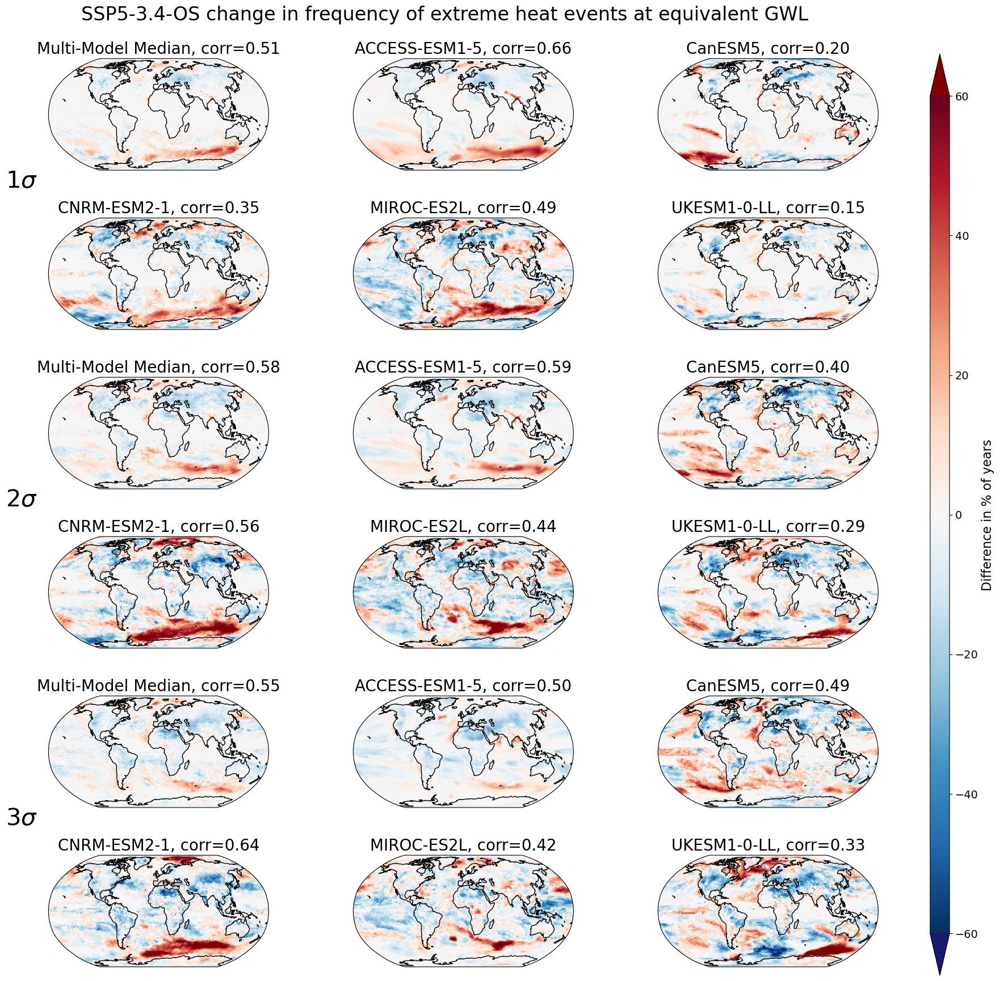

In [19]:
fig = plotting.plot_ext_freq_diff_corr_all_thresholds(
    differences=ssp_differences,
    expt='ssp534-over',
    ext_type='heat',
    gwl=None,
    period='equivalent',
    levels=None,
    # label='(c)',
    title='-1$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models = (),
    corr_dict=corr_differences,
    n_cols=3,
    suptitle = 'SSP5-3.4-OS change in frequency of extreme heat events at equivalent GWL',
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S27.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S28.jpg


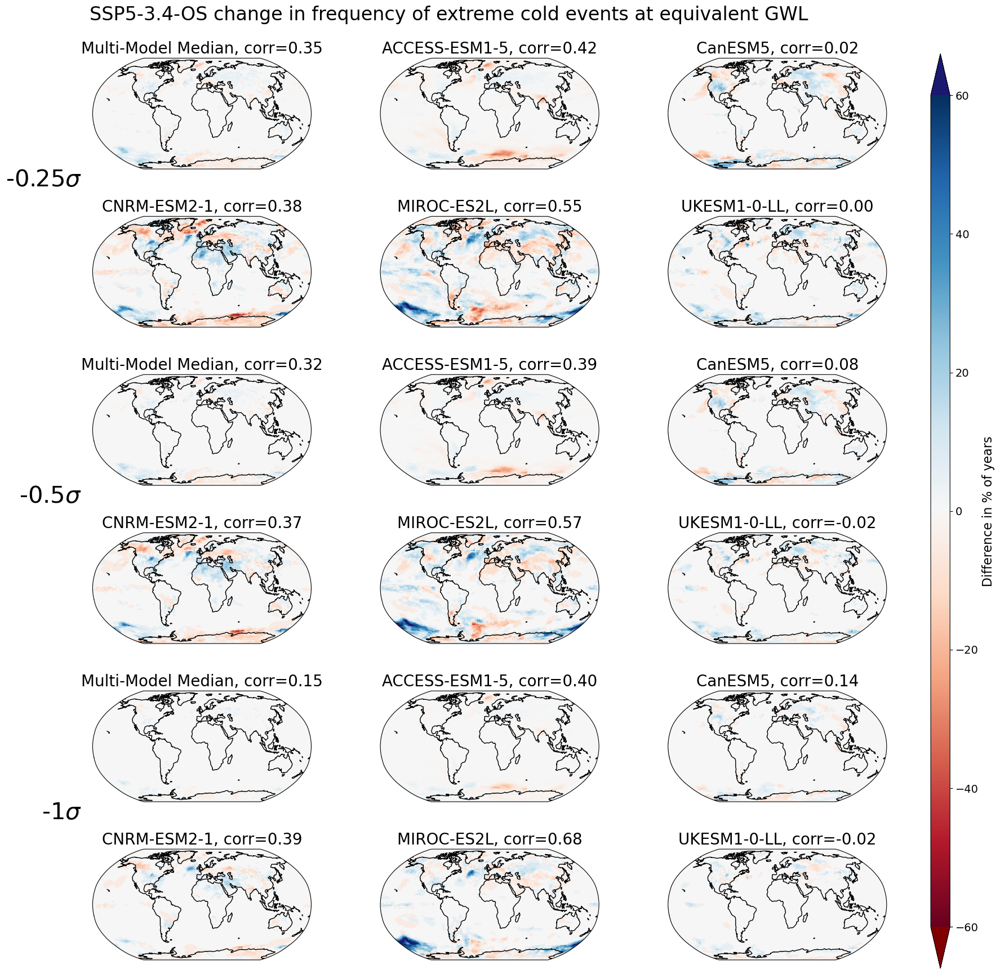

In [20]:
fig = plotting.plot_ext_freq_diff_corr_all_thresholds(
    differences=ssp_differences,
    expt='ssp534-over',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    levels=None,
    title='-1$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models = (),
    corr_dict=corr_differences,
    n_cols=3,
    suptitle = 'SSP5-3.4-OS change in frequency of extreme cold events at equivalent GWL',
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S28.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S25.jpg


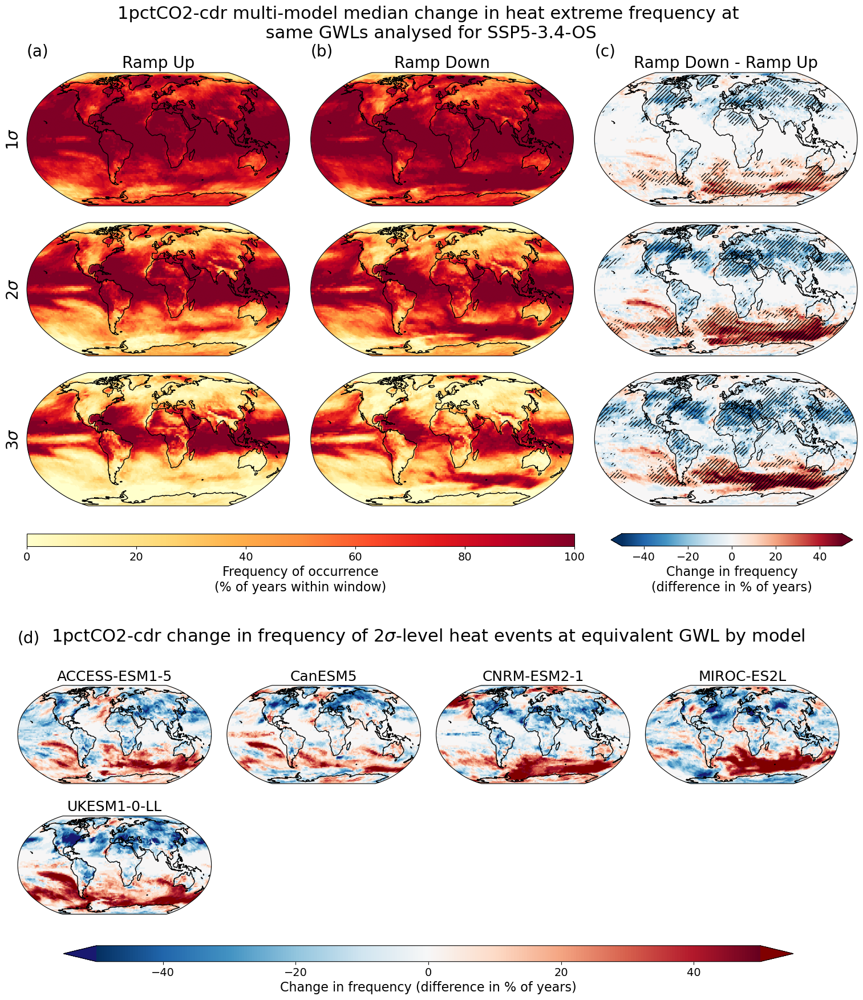

In [27]:
fig = plotting.plot_ext_freq_with_model_diffs(
    cdr_exceedances, cdr_differences, cdr_agreement,
    model='multi_model_median', expt='1pctCO2-cdr', ext_type='heat',
    gwl=None, period='equivalent', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    suptitle='1pctCO2-cdr multi-model median change in heat extreme frequency at\n same GWLs analysed for SSP5-3.4-OS',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S25.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S26.jpg


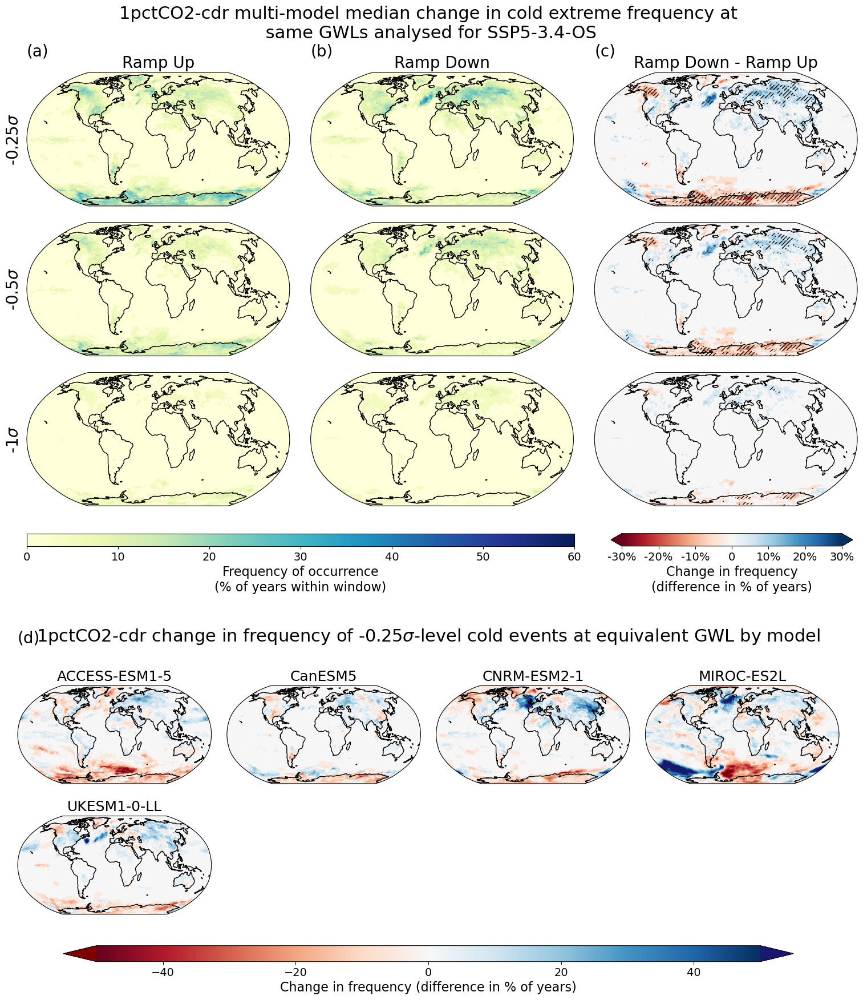

In [28]:
fig = plotting.plot_ext_freq_with_model_diffs(
    cdr_exceedances, cdr_differences, cdr_agreement,
    model='multi_model_median', expt='1pctCO2-cdr', ext_type='cold',
    gwl=None, period='equivalent', model_name='Multi-Model Median',
    diff_threshold='sigma1',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    suptitle='1pctCO2-cdr multi-model median change in cold extreme frequency at\n same GWLs analysed for SSP5-3.4-OS',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S26.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/main/figure_S21.jpg


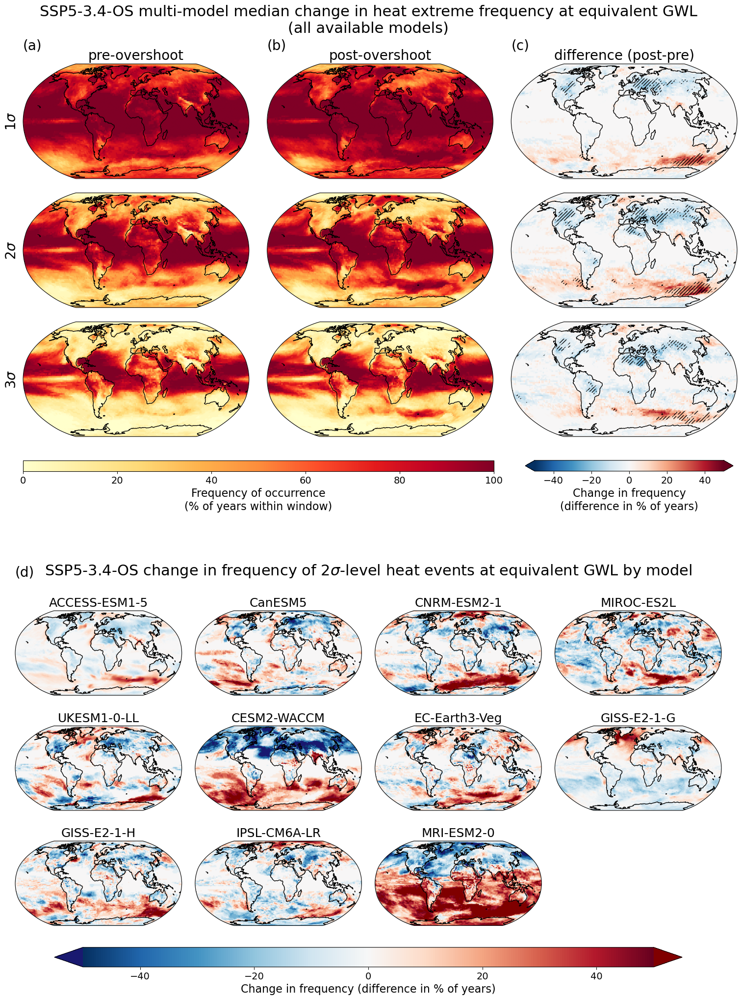

In [29]:
fig = plotting.plot_ext_freq_with_model_diffs(
    ssp_exceedances_all, ssp_differences_all, ssp_agreement_all,
    model='multi_model_median', expt='ssp534-over', ext_type='heat',
    gwl=None, period='equivalent', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    expt_name='SSP5-3.4-OS',
    suptitle='SSP5-3.4-OS multi-model median change in heat extreme frequency at equivalent GWL\n(all available models)',
    fig_dir=FIG_DIR, folder='main', file_name='figure_S21.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S22.jpg


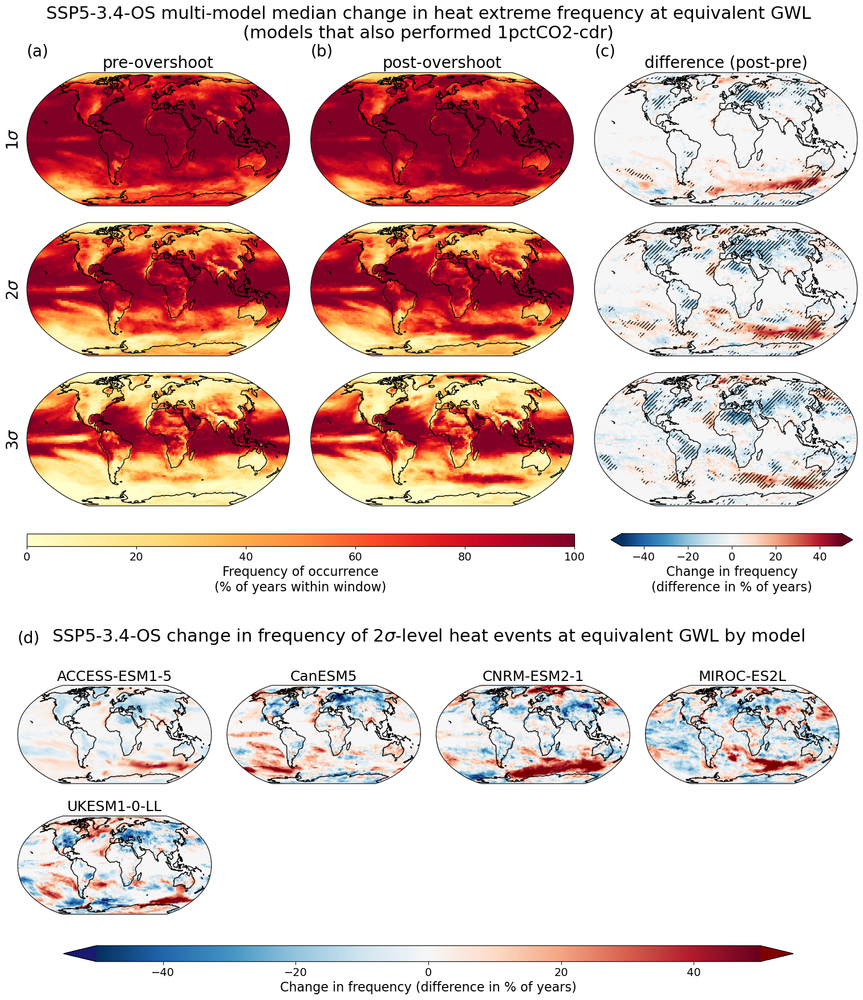

In [24]:
fig = plotting.plot_ext_freq_with_model_diffs(
    ssp_exceedances, ssp_differences, ssp_agreement,
    model='multi_model_median', expt='ssp534-over', ext_type='heat',
    gwl=None, period='equivalent', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    expt_name='SSP5-3.4-OS',
    suptitle='SSP5-3.4-OS multi-model median change in heat extreme frequency at equivalent GWL\n(models that also performed 1pctCO2-cdr)',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S22.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S23.jpg


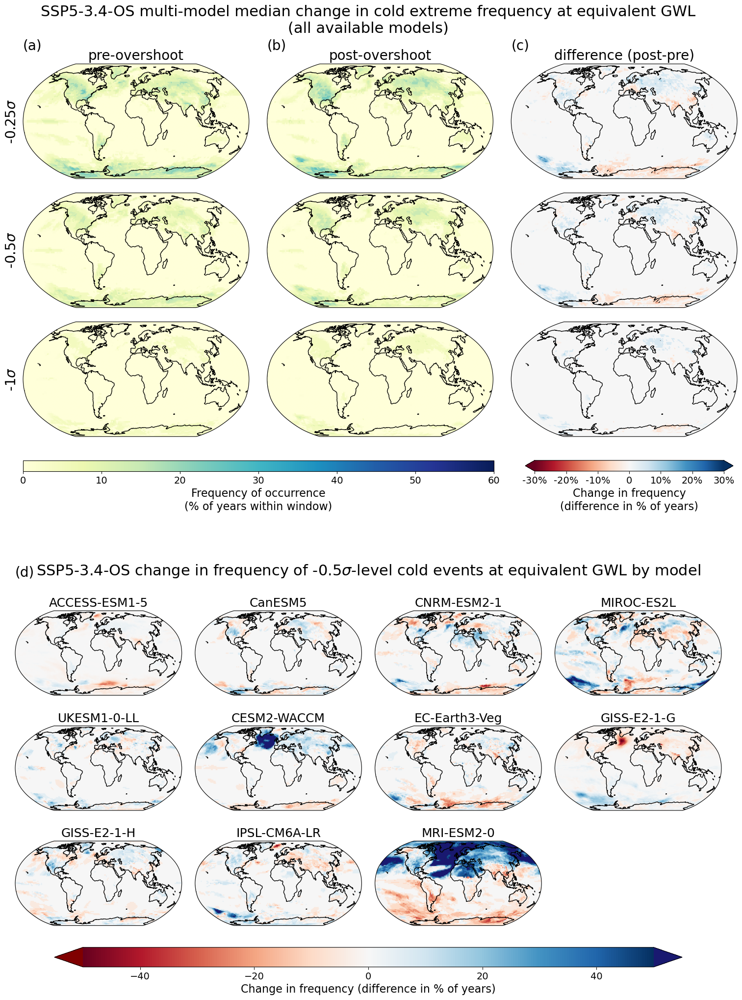

In [25]:
fig = plotting.plot_ext_freq_with_model_diffs(
    ssp_exceedances_all, ssp_differences_all, ssp_agreement_all,
    model='multi_model_median', expt='ssp534-over', ext_type='cold',
    gwl=None, period='equivalent', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    expt_name='SSP5-3.4-OS',
    suptitle='SSP5-3.4-OS multi-model median change in cold extreme frequency at equivalent GWL\n(all available models)',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S23.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S24.jpg


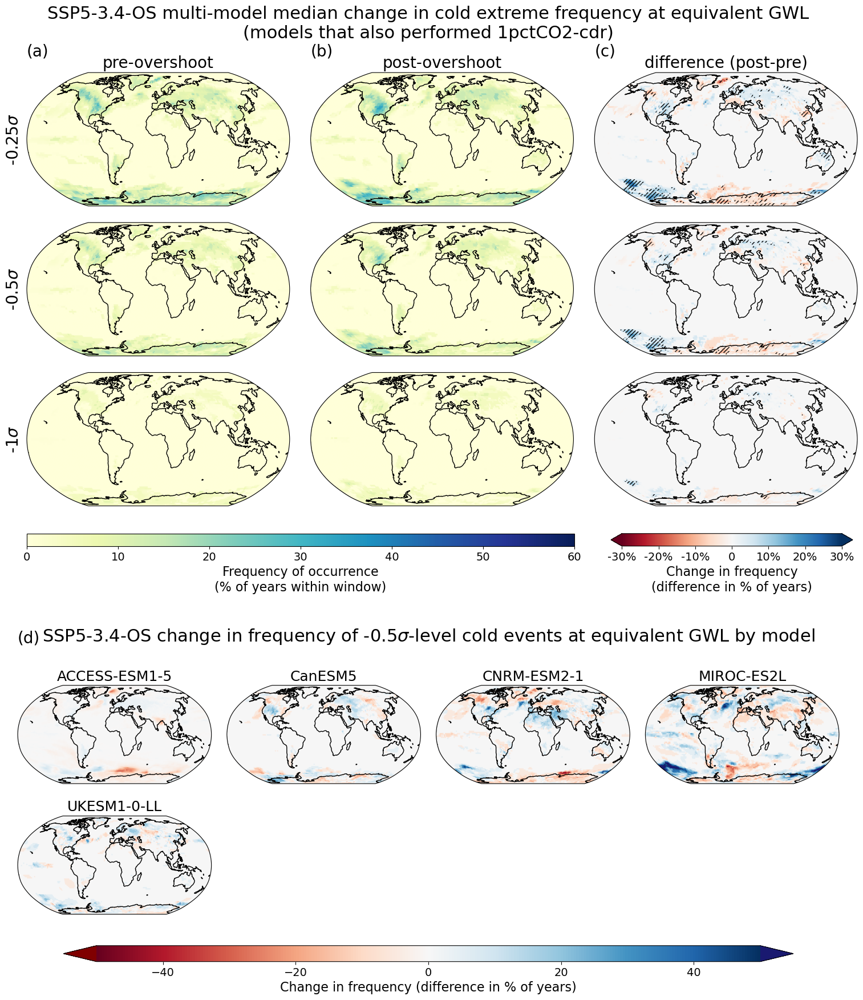

In [26]:
fig = plotting.plot_ext_freq_with_model_diffs(
    ssp_exceedances, ssp_differences, ssp_agreement,
    model='multi_model_median', expt='ssp534-over', ext_type='cold',
    gwl=None, period='equivalent', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    expt_name='SSP5-3.4-OS',
    suptitle='SSP5-3.4-OS multi-model median change in cold extreme frequency at equivalent GWL\n(models that also performed 1pctCO2-cdr)',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S24.jpg',
)